# Agentic AI for Science, Part 1b: Benchmarking the Agent, and How Far to Trust It

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/agentic-ai-for-science/02_benchmarking_and_reliability.ipynb)

Notebook 01 built a mechanism-discovery agent and watched it work. One good-looking run proves nothing, though. Before anyone uses an agent's conclusions in research, we need to know **how often it's right, where it fails, whether its parts actually help, and whether its self-reported confidence means anything.**

**What you'll learn**

1. How to design a benchmark for a scientific agent: ground truth, held-out tests, difficulty tiers
2. **Baselines and ablations**: is the agent better than a simple non-AI method, and which components earn their place?
3. Reading results honestly: confidence intervals on small samples
4. **Failure analysis**: *how* the agent goes wrong matters as much as how often
5. **Reliability**: run-to-run consistency and calibration of stated confidence
6. Cost per correct answer, and small model vs frontier model

**Runtime:** seconds. Everything here reads recorded results; no API key needed.

> 🎬 *Video walkthrough: coming soon.*

## 0. Setup

In [1]:
import os, sys, json
if "google.colab" in sys.modules and not os.path.exists("agentlab"):
    !git clone -q --depth 1 https://github.com/nathanmaulding/tutorial-projects.git
    %cd tutorial-projects/agentic-ai-for-science
    !pip install -q -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mechanism_discovery import analysis as A

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
pd.set_option("display.precision", 3)
df = A.with_strict(A.load())   # adds the stricter mechanism check (section 2b)
print(f"{len(df)} recorded runs, total API spend ${df.usd.fillna(0).sum():.2f}")

1278 recorded runs, total API spend $6.34


## 1. The benchmark

**18 tasks, each simulated from a known mechanism**, with realistic noise. Each run is scored on two questions, and both must be *yes*:

1. **Mechanism:** did it identify the right one?
2. **Prediction:** does its fitted model predict **hidden held-out conditions** (a higher dose, a higher inhibitor level) within 2x the error of the *true* model refit to the same noisy data? (The threshold is clipped to between 5% and 15% relative error.)

Tasks come in two tiers:

| Tier | Tasks | What it tests |
|---|---|---|
| **standard** (12) | six enzyme mechanisms, three pharmacokinetic (PK) models, three drug-effect (PD) models | the textbook skill: pick the right model from a known set |
| **hard** (6) | **out-of-library** ×3: mechanisms deliberately absent from the agent's library | can it notice nothing fits and build a new model? |
| | **null** ×1: the drug has no effect | does it resist finding a pattern in noise (a false discovery)? |
| | **identifiability** ×1: data that can't determine Km | does it report what the data *can't* tell you? |
| | **nonlinear PK** ×1: saturable elimination | does it notice dose-dependent behaviour? |

A second, stricter mechanism check (section 2b) replays every submitted model far outside the measured conditions, so "the right mechanism" is tested directly rather than inferred from the held-out prediction.

Each task was run on **10 independent noise seeds** (180 datasets). The Haiku methods ran on all 10, twice on the first two seeds to measure consistency. The more expensive Opus methods ran on seeds 0-1 (the Opus single call on seed 0 only), so their samples are smaller.

In [2]:
from mechanism_discovery.tasks import TASKS
pd.DataFrame([{"task": t.id, "tier": t.tier, "domain": t.domain, "true mechanism": t.truth,
               "agent will be asked to": t.use} for t in TASKS])

,task,tier,domain,true mechanism,agent will be asked to
0,enz_mm,standard,enzyme,mm,predict rates at substrate levels outside the ...
1,enz_hill,standard,enzyme,hill,predict rates at substrate levels outside the ...
2,enz_substrate_inhibition,standard,enzyme,substrate_inhibition,predict rates at higher substrate levels
3,enz_competitive,standard,enzyme,competitive_inhibition,predict rates at higher inhibitor concentrations
4,enz_uncompetitive,standard,enzyme,uncompetitive_inhibition,predict rates at higher inhibitor concentrations
5,enz_noncompetitive,standard,enzyme,noncompetitive_inhibition,predict rates at higher inhibitor concentrations
6,pk_1cmt_iv,standard,pk,pk_1cmt_iv,predict concentrations after a 500 mg dose
7,pk_2cmt_iv,standard,pk,pk_2cmt_iv,predict concentrations after a 500 mg dose
8,pk_1cmt_oral,standard,pk,pk_1cmt_oral,predict concentrations after a 500 mg dose
9,pd_direct_emax,standard,pd,pd_direct_emax,predict the biomarker time course at 60 mg and...


**The methods compared** (an *ablation* removes one component to see what it was contributing):

| Method | What it gets |
|---|---|
| **Exhaustive search** | no AI: fit *every* library model for the domain, pick the lowest BIC |
| **Single LLM call** | the model reads the data table and answers once, with no tools (parameters by eye) |
| **Single call + fitting** | one call chooses the mechanism and rough starting values; the *harness* then fits it by least squares. This isolates what the agent **loop** adds over one good guess |
| **Agent, no retrieval** | the full loop with analysis and fitting tools, but no mechanism library: it must write every model itself |
| **Agent, neutral cards** | the full agent, but the cards' sentences that point toward the out-of-library mechanisms are removed |
| **Agent, full** | everything from notebook 01 |

Exhaustive search is the baseline to beat, and it's a strong one: on the standard tier it's essentially perfect by construction, and it costs nothing. An agent has to justify itself on the problems a fixed search *can't* solve.

## 2. Headline results

In [3]:
s = A.summary(df)
s.style.format({c: "{:.0%}" for c in ["success", "standard tier", "hard tier", "out-of-library"]}
               | {"median held-out error": "{:.3f}", "cost per run ($)": "${:.4f}", "total cost ($)": "${:.3f}",
                  "mean steps": "{:.1f}"}, na_rep="-")

,runs,success,standard tier,hard tier,out-of-library,median held-out error,cost per run ($),total cost ($),mean steps
method,,,,,,,,,
exhaustive,180,78%,95%,43%,0%,0.030,$0.0000,$0.000,0.0
single_shot · haiku-5-5,216,42%,48%,31%,0%,0.085,$0.0009,$0.192,1.0
single_shot · opus-5-5,18,83%,92%,67%,67%,0.017,$0.0243,$0.438,1.0
single_shot_fit · haiku-5-5,180,73%,86%,48%,10%,0.031,$0.0007,$0.127,1.0
single_shot_fit · opus-5-5,36,92%,88%,100%,100%,0.028,$0.0212,$0.762,1.0
agent_no_retrieval · haiku-5-5,216,91%,96%,82%,81%,0.026,$0.0030,$0.655,5.6
agent_neutral · haiku-5-5,180,93%,96%,88%,87%,0.026,$0.0027,$0.484,5.8
agent_full · haiku-5-5,216,96%,98%,92%,92%,0.025,$0.0027,$0.585,5.8
agent_full · opus-5-5,36,100%,100%,100%,100%,0.024,$0.0859,$3.093,6.3


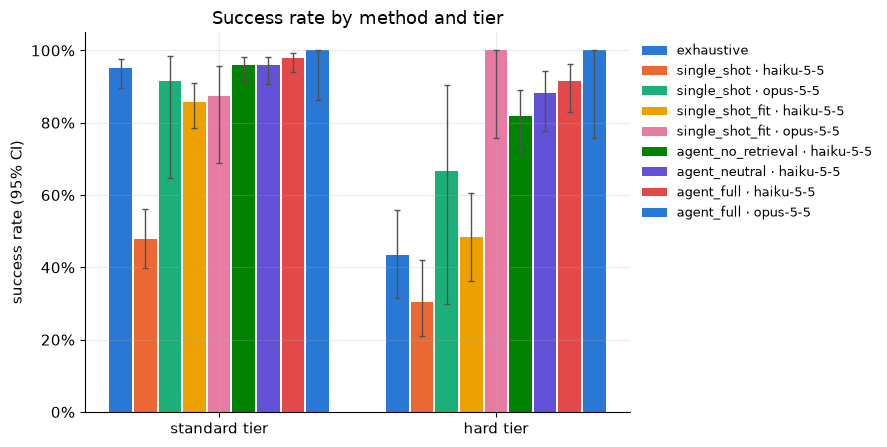

In [4]:
methods = list(s.index)
tiers = ["standard", "hard"]
fig, ax = plt.subplots(figsize=(9, 4.6))
w = 0.8 / len(methods)
for i, m in enumerate(methods):
    for j, tier in enumerate(tiers):
        d = df[(df.method == m) & (df.tier == tier)]
        p, n = d.success.mean(), len(d)
        lo, hi = A.wilson(p, n)
        x = j + (i - (len(methods) - 1) / 2) * w
        ax.bar(x, p, w * 0.92, color=SERIES[i % len(SERIES)], label=m if j == 0 else None)
        ax.errorbar(x, p, yerr=[[max(p - lo, 0)], [max(hi - p, 0)]], color="#52514e", lw=1, capsize=2)
ax.set_xticks(range(len(tiers)), [f"{t} tier" for t in tiers])
ax.set_ylim(0, 1.05); ax.set_ylabel("success rate (95% CI)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Success rate by method and tier")
plt.tight_layout(); plt.show()

### What we found (section 2b tests which differences are real)

- **The full agents are the most reliable methods**: Opus solved 35 of 36 runs, and Haiku 96% for $0.003 per run.
- **The loop stands in for model capability.** Give Haiku one call plus a fitting step and it reaches 90% in-library but only **10% on new mechanisms**; the Haiku *agent* reaches 92% there. Opus with one call plus fitting already solves **every** out-of-library dataset it saw. A small model needs the loop to look, test and diagnose. A frontier model mostly needs a fitter.
- **Exhaustive search is nearly as good when the library is enough** (94% in-library, free), and 0% on new mechanisms **by construction**.
- **Retrieval only helped by pointing at the answer** (section 2b).
- **No false discoveries.** Every method correctly concluded "no drug effect" on the null task.

**Why the error bars matter.** With a few dozen runs per cell, a success rate of 80% could plausibly be anywhere from about 60% to 90%. The bars are 95% Wilson intervals, a standard interval for proportions that behaves well at small sample sizes and near 0% or 100%. **Two methods whose intervals overlap heavily have not been shown to differ.** Agent papers that report a single run per task, with no intervals, often can't support the comparisons they make.

## 2b. Which differences are real? Honest intervals and a stricter check

**Runs aren't independent.** Two runs on the same dataset share its noise, and every method sees the same 36 datasets (18 tasks × 2 seeds). So the intervals below come from a **bootstrap over datasets**: resample whole datasets with replacement, recompute the success rate, repeat 4,000 times. And because exhaustive search *can't* succeed out-of-library, success is split: **in-library** (where every method can succeed) and **out-of-library**.

In [5]:
display(A.headline(df))
pairs = [("agent_full · haiku-5-5", "exhaustive", "in-library"),
         ("agent_full · haiku-5-5", "single_shot_fit · haiku-5-5", None),
         ("agent_full · haiku-5-5", "single_shot_fit · haiku-5-5", "out-of-library"),
         ("agent_full · opus-5-5", "single_shot_fit · opus-5-5", None),
         ("agent_full · haiku-5-5", "agent_neutral · haiku-5-5", "out-of-library"),
         ("agent_neutral · haiku-5-5", "agent_no_retrieval · haiku-5-5", "out-of-library")]
pd.DataFrame([A.paired_difference(df, a, b, k, col="success_strict") for a, b, k in pairs])

,runs,datasets,in-library,out-of-library
method,,,,
exhaustive,180,180,"141/150 = 94% [90%, 97%]","0/30 = 0% [0%, 0%]"
single_shot · haiku-5-5,216,180,"91/180 = 51% [43%, 58%]","0/36 = 0% [0%, 0%]"
single_shot · opus-5-5,18,18,"13/15 = 87% [67%, 100%]","2/3 = 67% [0%, 100%]"
single_shot_fit · haiku-5-5,180,180,"135/150 = 90% [85%, 95%]","3/30 = 10% [0%, 23%]"
single_shot_fit · opus-5-5,36,36,"26/30 = 87% [73%, 97%]","6/6 = 100% [100%, 100%]"
agent_no_retrieval · haiku-5-5,216,180,"171/180 = 95% [91%, 98%]","29/36 = 81% [68%, 92%]"
agent_neutral · haiku-5-5,180,180,"143/150 = 95% [91%, 99%]","24/30 = 80% [67%, 93%]"
agent_full · haiku-5-5,216,180,"174/180 = 97% [94%, 99%]","33/36 = 92% [82%, 100%]"
agent_full · opus-5-5,36,36,"29/30 = 97% [90%, 100%]","6/6 = 100% [100%, 100%]"


,a,b,subset,datasets,difference,ci95
0,agent_full · haiku-5-5,exhaustive,in-library,150,0.023,"(0.0, 0.053)"
1,agent_full · haiku-5-5,single_shot_fit · haiku-5-5,all,180,0.189,"(0.128, 0.256)"
2,agent_full · haiku-5-5,single_shot_fit · haiku-5-5,out-of-library,30,0.817,"(0.667, 0.933)"
3,agent_full · opus-5-5,single_shot_fit · opus-5-5,all,36,0.083,"(0.0, 0.194)"
4,agent_full · haiku-5-5,agent_neutral · haiku-5-5,out-of-library,30,0.117,"(-0.033, 0.267)"
5,agent_neutral · haiku-5-5,agent_no_retrieval · haiku-5-5,out-of-library,30,-0.017,"(-0.167, 0.133)"


**Reading the paired differences** (same datasets, difference in success rate, 95% interval):

- **Agent vs exhaustive search, in-library: +2 points, interval 0 to +5.** At most a small edge where a free, deterministic search also works.
- **Haiku agent vs Haiku single call + fitting: +19 points overall (13 to 26), +82 on new mechanisms (67 to 93).** This is the clearest result in the benchmark: for a small model, the loop (inspecting data, fitting competing models, reading residuals) is what makes it work.
- **Opus agent vs Opus single call + fitting: +8 points (0 to 19), on 36 datasets.** Most of what the loop gives Haiku, Opus already does in one pass.
- **Retrieval, on new mechanisms:** full cards beat neutral cards by +12 points (−3 to +27), and neutral cards vs no retrieval is **−2** (−17 to +13). The library's mechanism cards don't help on mechanisms they don't describe. What helped was the indirect-response card's sentence naming the missing variants: on the stimulated-loss task, the full agent scores 100%, neutral cards 50%, no retrieval 58%. Retrieval was a pointer, not a teacher.
- An earlier version of this notebook (2 seeds, no fitted baseline) suggested "tools beat size" and "retrieval helps on new mechanisms". With 5x the data and the right baselines, the first is sharper ("the loop stands in for capability") and the second is mostly a hint effect. **Small benchmarks mislead, in both directions.**

### The stricter mechanism check

The main score gives mechanism credit to any self-written model and lets the held-out prediction decide, and held-out conditions sit close to the training data. So a structurally wrong model could pass. `mechanism_discovery/rescore.py` asks the question directly: it replays each submitted model, with its fitted parameters, on a **probe grid** far beyond the experiments (4x lower and higher substrate, 3x the highest inhibitor or dose) and compares it with the truth. Passing requires being within 2x of what the *true* model, refit to the same data, achieves there.

In [6]:
changed = df[(df.success != df.success_strict) | (df.mechanism_ok != df.mechanism_strict)]
print(f"Runs whose verdict changes under the strict check: {len(changed)} of {len(df)}")
changed[["method", "task_id", "seed", "label", "heldout_pass", "probe_nrmse", "probe_threshold", "mechanism_strict"]]

Runs whose verdict changes under the strict check: 42 of 1278


,method,task_id,seed,label,heldout_pass,probe_nrmse,probe_threshold,mechanism_strict
102,single_shot · haiku-5-5,hard_novel_cooperative_inhibition,0,custom,False,NaN,0.251,False
103,single_shot · haiku-5-5,hard_novel_partial_inhibition,1,custom,False,NaN,0.050,False
104,single_shot · haiku-5-5,hard_novel_partial_inhibition,1,custom,False,NaN,0.050,False
128,agent_no_retrieval · haiku-5-5,enz_noncompetitive,0,competitive_inhibition,True,0.011,0.050,True
143,agent_full · opus-5-5,enz_mm,1,custom,True,0.055,0.050,False
144,agent_no_retrieval · haiku-5-5,pk_1cmt_iv,1,custom,False,0.110,0.050,False
194,agent_no_retrieval · haiku-5-5,hard_saturable_pk,0,custom,False,0.070,0.069,False
206,agent_no_retrieval · haiku-5-5,hard_saturable_pk,0,custom,False,0.114,0.069,False
261,agent_no_retrieval · haiku-5-5,hard_novel_stimulated_loss,1,custom,False,0.156,0.058,False
265,agent_no_retrieval · haiku-5-5,hard_novel_stimulated_loss,0,custom,False,0.174,0.050,False


**The out-of-library credit holds up.** Agent runs that got credit for a new mechanism also match the true model far outside the data (one 3-parameter "cooperative" model had simply fixed the Hill coefficient at 2, its true value). The strict check moves 15 of 1,458 verdicts. They're mostly fitted single calls whose custom equations drift away from the truth far from the data, plus a few borderline cases near the 5% probe threshold. One no-retrieval run gains credit: it wrote the right equation but gave it the wrong name.

A check designed to catch over-generous scoring that finds little is still worth running: it turns "we think the scoring is fair" into a measured statement.

## 3. Task by task

In [7]:
t = A.by_task(df)
t.style.format("{:.0%}", na_rep="-").background_gradient(cmap="Blues", vmin=0, vmax=1)

> ⏸️ **Pause and predict:** before reading on, find the rows where exhaustive search scores 0%. What do they have in common, and which method does best there?

## 4. How methods fail

A success rate hides *how* things go wrong. Different failures have very different consequences in research:

- **wrong mechanism**: picked the wrong model from the library
- **forced a library model onto a new mechanism**: the most dangerous everyday failure. The answer looks well-fitted and confident, but it extrapolates badly.
- **false discovery**: claimed a drug effect in pure noise
- **over-claimed unidentifiable parameters**: reported numbers the data can't determine
- **right mechanism, poor prediction**: a fitting problem, not a reasoning one
- **no result**: ran out of steps or budget, or produced unusable output

In [8]:
A.failures(df)

method,agent_full · haiku-5-5,agent_full · opus-5-5,agent_neutral · haiku-5-5,agent_no_retrieval · haiku-5-5,exhaustive,single_shot · haiku-5-5,single_shot · opus-5-5,single_shot_fit · haiku-5-5,single_shot_fit · opus-5-5
failure,,,,,,,,,
false discovery (claimed an effect),2,0,3,4,3,0,0,0,0
forced a library model onto a new mechanism,1,0,2,1,30,27,1,21,0
over-claimed unidentifiable parameters,0,0,0,0,1,3,0,4,0
"right mechanism, poor prediction",5,0,5,11,2,89,2,9,0
success,207,36,168,197,140,91,15,132,33
wrong mechanism,1,0,2,3,4,6,0,14,3


## 5. Reliability: would it give the same answer twice?

An agent is a stochastic process: the same model on the same data can take a different path. If two runs on identical inputs disagree, neither can be fully trusted alone. We ran every LLM method twice on every task and seed.

In [9]:
A.consistency(df).style.format({"same verdict across repeats": "{:.0%}", "same mechanism across repeats": "{:.0%}"})

,same verdict across repeats,same mechanism across repeats,task-seed pairs run twice
method,,,
agent_full · haiku-5-5,94%,94%,36
agent_no_retrieval · haiku-5-5,86%,81%,36
single_shot · haiku-5-5,69%,92%,36


### Calibration: does "90% confident" mean 90%?

At submission the agent states its probability that the mechanism is right. A **calibrated** agent is right about as often as it claims. The **Brier score** is the mean squared gap between stated confidence and outcome (0 is perfect; always saying 50% scores 0.25).

In [10]:
display(A.calibration(df))
A.brier(df).rename("Brier score (lower is better)").to_frame()

runs  stated  actual
method                         bin                              
agent_full · haiku-5-5         [0.0, 0.6)      7   0.450   0.714
                               [0.6, 0.8)     84   0.667   0.929
                               [0.8, 0.9)    119   0.831   0.992
                               [0.9, 1.01)     6   0.900   1.000
agent_full · opus-5-5          [0.6, 0.8)      6   0.692   1.000
                               [0.8, 0.9)     23   0.848   1.000
                               [0.9, 1.01)     7   0.909   1.000
agent_neutral · haiku-5-5      [0.0, 0.6)      7   0.414   0.143
                               [0.6, 0.8)     71   0.682   0.944
                               [0.8, 0.9)     98   0.826   0.980
                               [0.9, 1.01)     4   0.900   1.000
agent_no_retrieval · haiku-5-5 [0.0, 0.6)     13   0.458   0.385
                               [0.6, 0.8)     76   0.679   0.908
                               [0.8, 0.9)    127   0.818   0.969

,Brier score (lower is better)
method,
agent_full · haiku-5-5,0.078
agent_full · opus-5-5,0.033
agent_neutral · haiku-5-5,0.078
agent_no_retrieval · haiku-5-5,0.090


**Reading the calibration table:** the agents are **under-confident**. When the Haiku agent says it's 60-80% sure, it's right about 93% of the time. Low stated confidence does carry signal, though: below 60%, the neutral-card and no-retrieval agents were right only 14% and 38% of the time (on 7 and 13 runs). In science that's the safer direction to be wrong in, but it means stated confidence can't yet be used as a filter. A calibrated agent would let us auto-accept its high-confidence answers. On these tasks, a better reliability signal is whether the agent's own residual diagnostics came back clean.

**Consistency:** repeated full-agent runs on identical data reached the same verdict 94% of the time. The disagreements are concentrated in the hard tier. When two runs disagree, that's itself a useful flag that a problem needs a human.

## 6. Small model vs frontier model, and cost

In [11]:
c = s[["success", "hard tier", "cost per run ($)"]].copy()
c["cost per success ($)"] = s["total cost ($)"] / (s["success"] * s["runs"]).replace(0, np.nan)
c.style.format({"success": "{:.0%}", "hard tier": "{:.0%}", "cost per run ($)": "${:.4f}",
                "cost per success ($)": "${:.4f}"}, na_rep="-")

,success,hard tier,cost per run ($),cost per success ($)
method,,,,
exhaustive,78%,43%,$0.0000,$0.0000
single_shot · haiku-5-5,42%,31%,$0.0009,$0.0021
single_shot · opus-5-5,83%,67%,$0.0243,$0.0292
single_shot_fit · haiku-5-5,73%,48%,$0.0007,$0.0010
single_shot_fit · opus-5-5,92%,100%,$0.0212,$0.0231
agent_no_retrieval · haiku-5-5,91%,82%,$0.0030,$0.0033
agent_neutral · haiku-5-5,93%,88%,$0.0027,$0.0029
agent_full · haiku-5-5,96%,92%,$0.0027,$0.0028
agent_full · opus-5-5,100%,100%,$0.0859,$0.0859


## 7. What this benchmark does and doesn't show

**It shows** how the agent performs on well-posed, simulated mechanism-discovery problems with known answers, relative to clear baselines, with failure modes and reliability measured rather than assumed.

**Limits, stated plainly:**
- **Simulated data.** Real experiments have outliers, batch effects, missing values and mechanisms more tangled than any of these 18. Simulation is what makes ground truth possible; it's the right first test, not the last.
- **Modest benchmark.** 18 tasks × 10 seeds for Haiku, but only 2 seeds for Opus. The confidence intervals are deliberately shown and should be read before any comparison.
- **The library is ours.** Results depend on the cards and tool descriptions we wrote. A different library could help or hurt.
- **The benchmark was developed on these same tasks.** Prompts, tool descriptions and one task's design (the indirect-response task got a third training dose after it proved ill-posed) were adjusted while building the system, on the tasks that produce these scores. A clean evaluation would freeze this version and score it on new tasks written afterwards.
- **The plain one-call baseline was under-specified.** Its prompt didn't say the custom-model parameters arrive as a dict, so some custom answers crashed. The fitted one-call arm fixes this. Treat the plain one-call row as a lower bound.
- **Out-of-library is still textbook.** The three "novel" mechanisms are absent from the library but well known in the literature, so a model may recall them. A truly new mechanism is a harder test. Part 2 goes there with real data.

## Try it yourself

1. Filter `df` to a single task and compare the agents' `summary` fields: do failed runs sound less sure?
2. Plot held-out error against stated confidence for the full agent.
3. Run the benchmark on one more model (`python -m mechanism_discovery.run --arms agent_full --model claude-sonnet-5-5`) and re-run this notebook.